#**Fine-Tuning of Large Language Models**

#Install Required Packages

In [1]:
!pip install -q transformers
!pip install -q datasets
!pip install -q peft
!pip install -q accelerate
!pip install -q bitsandbytes
!pip install -q sentencepiece
!pip install -q scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 MB 13.7 MB/s eta 0:00:00


In [2]:
!pip install --upgrade transformers peft accelerate datasets

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 938.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 52.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 85.7 MB/s eta 0:00:00
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.21.4
    Uninstalling tokenizers-0.21.4:
      Successfully uninstalled tokenizers-0.21.4
  Attempting uninstall: transformers
    Found existing installation: transformers 4.55.4
    Uninstalling transformers-4.55.4:
      Successfully uninstalled transformers-4.55.4


# Environment Setup and Imports

In [3]:
import os
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import warnings
from collections import Counter
from typing import List, Dict, Any

warnings.filterwarnings('ignore')

# Check GPU availability and specifications
print("=" * 60)
print("SYSTEM INFORMATION")
print("=" * 60)
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
    print(f"Current GPU Memory Used: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")
else:
    print("WARNING: No GPU detected! This notebook requires GPU.")

SYSTEM INFORMATION
PyTorch version: 2.8.0+cu126
CUDA available: True
GPU Device: Tesla T4
GPU Memory: 14.74 GB
Current GPU Memory Used: 0.00 GB


# Import Hugging Face Libraries

In [4]:
from huggingface_hub import login, hf_hub_download
from datasets import Dataset, DatasetDict
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
)
from peft import (
    LoraConfig,
    PromptTuningConfig,
    PromptTuningInit,
    get_peft_model,
    PeftModel,
    TaskType,
    prepare_model_for_kbit_training
)

# Hugging Face Authentication

YOUR_HF_TOKEN

In [5]:
import os
# Replace with your Hugging Face token
HF_TOKEN = os.environ.get("HF_TOKEN")  # set your Hugging Face token as an environment variable

# Login to Hugging Face
def authenticate_huggingface(token):
    """Authenticate with Hugging Face Hub"""
    try:
        login(token=token)
        print("✓ Successfully authenticated with Hugging Face!")
        return True
    except Exception as e:
        print(f"✗ Authentication failed: {e}")
        print("Please ensure you have a valid token from https://huggingface.co/settings/tokens")
        return False

# Authenticate
if HF_TOKEN != "hf_YOUR_TOKEN_HERE":
    authenticated = authenticate_huggingface(HF_TOKEN)
else:
    print("⚠️ Please replace HF_TOKEN with your actual Hugging Face token")

✓ Successfully authenticated with Hugging Face!


# Download and Filter Dataset

The SlimOrca dataset contains conversations in various formats. We need to filter for the correct format: `system -> user -> assistant`

In [6]:
def download_and_analyze_dataset():
    """Download dataset and analyze its structure"""

    repo_id = "miladmim/slim-orca-dedup-chat-50k-persian"
    filename = "data.jsonl"

    print(f"Downloading dataset from: {repo_id}")
    print("This may take a few minutes...")

    try:
        # Download the dataset file
        file_path = hf_hub_download(
            repo_id=repo_id,
            filename=filename,
            repo_type="dataset"
        )
        print(f"Dataset downloaded to: {file_path}")

        # Analyze dataset structure
        all_data = []
        pattern_counter = Counter()

        with open(file_path, 'r', encoding='utf-8') as f:
            for line_num, line in enumerate(f):
                try:
                    conversation = json.loads(line.strip())
                    all_data.append(conversation)

                    # Analyze conversation pattern
                    roles = [msg.get('role', 'unknown') for msg in conversation]
                    pattern = " -> ".join(roles)
                    pattern_counter[pattern] += 1

                except json.JSONDecodeError:
                    print(f"Skipping malformed line {line_num + 1}")

        print(f"\n Total conversations loaded: {len(all_data)}")
        print("\nConversation patterns found:")
        for pattern, count in pattern_counter.most_common(5):
            print(f"  - {pattern}: {count} samples")

        return all_data, pattern_counter

    except Exception as e:
        print(f"Error downloading dataset: {e}")
        return None, None

# Download and analyze
raw_data, patterns = download_and_analyze_dataset()

This may take a few minutes...


data.jsonl:   0%|          | 0.00/97.8M [00:00<?, ?B/s]

Dataset downloaded to: /root/.cache/huggingface/hub/datasets--miladmim--slim-orca-dedup-chat-50k-persian/snapshots/cbd7045a43dd3324fb98cf9dc37b9c0d5fcfb0d8/data.jsonl

 Total conversations loaded: 40458

Conversation patterns found:
  - system -> user -> assistant: 39933 samples
  - system -> assistant: 453 samples
  - system -> user: 33 samples
  - system -> user -> user: 14 samples
  - system -> user -> assistant -> assistant: 7 samples


# Filter Dataset for Correct Format

In [7]:
def filter_dataset(data: List, target_pattern: str = 'system -> user -> assistant'):
    """Filter dataset to keep only conversations with the correct format"""

    filtered_data = []

    print(f"Filtering for pattern: {target_pattern}")

    for conversation in tqdm(data, desc="Filtering conversations"):
        # Check conversation pattern
        roles = [msg.get('role', 'unknown') for msg in conversation]
        pattern = " -> ".join(roles)

        if pattern == target_pattern:
            filtered_data.append(conversation)

    print(f"Filtered dataset: {len(filtered_data)} valid conversations")
    print(f"Removed: {len(data) - len(filtered_data)} invalid conversations")

    return filtered_data

# Filter the dataset
filtered_conversations = filter_dataset(raw_data)

Filtering for pattern: system -> user -> assistant


Filtering conversations:   0%|          | 0/40458 [00:00<?, ?it/s]

Filtered dataset: 39933 valid conversations
Removed: 525 invalid conversations


# Part 1: Data Exploration and Model Selection (10 points)

# Data and Model Selection (10 Points)
## 1. Data Loading and Structure Analysis

Loading: The miladmim/slim-orca-dedup-chat-50k-persian dataset was successfully downloaded from the Hugging Face Hub. This dataset contains 50,000 conversational samples in Persian.

Data Structure: Each sample in the dataset is a conversation with a specific format. As observed in the code and output samples, the dominant and required structure is a list of messages following a `system -> user -> assistant` pattern:

- **System:** This message defines the role and persona of the AI assistant (e.g., "You are an AI assistant...").

- **User:** This message contains the task or question posed by the user to the model.

- **Assistant:** This is the ideal and expected response from the model, which is used for training.

Analysis and Advantages of the Data Format:
This three-part format is highly effective for Instruction Fine-Tuning because:

Role-based Learning: The model explicitly learns to respond to a "user" command according to its "system" persona.

Clear Separation of Task and Response: The boundary between the input (user's instruction) and the desired output (assistant's response) is well-defined, leading to more stable training.

Contextualization: The system message provides the model with a context to frame its responses, helping it avoid generic or irrelevant answers.

Suitability for Chat-Tuned Models: Models like Gemma-IT are pre-trained with this format, and using the same structure during fine-tuning maximizes effectiveness.

## 2. Model Selection
**Base vs. Instruct Models:**

- Base Model: A model that has completed its pre-training on a massive corpus of text (like the internet). It excels at fluent text generation and predicting the next word but is not inherently good at following user commands.

- Instruct Model: A version of the Base model that has undergone an additional training phase called Instruction Fine-Tuning. In this phase, the model is trained on a dataset of "instruction-response" pairs to acquire the ability to understand and execute user commands accurately. These models are better suited for assistant-like applications.

Selected Model and Rationale:
The google/gemma-2-2b-it model was chosen. This decision was based on the following reasons:

Instruct Version: The -it suffix indicates the model is "Instruction Tuned," which aligns perfectly with the project's goal of instruction fine-tuning.

Optimal Size: With 2 billion parameters, this model strikes a good balance between performance and computational requirements, making it trainable on standard GPUs (like the T4 in Colab/Kaggle).

Multilingual Support: Gemma-2 has adequate performance in the Persian language, which was essential for this project.

Tool Compatibility: The model is well-supported by the Transformers and PEFT libraries.

## 3. Data Preparation and Initial Testing
Tokenizer and Processing: The tokenizer for the gemma-2-2b-it model was loaded. The data was formatted into the model's standard input format using the tokenizer.apply_chat_template method. This process automatically adds special tokens like `start_of_turn` and `end_of_turn` to delineate roles, which is critical for the model's performance.

Analysis of Base Model Performance (Before Training):
By examining the base_model_results.json file, the model's performance before any fine-tuning was assessed:

**Weaknesses:**

Input Repetition: In many cases, the model simply repeated the input prompt.

Irrelevant Responses: The outputs were often unrelated to the user's actual question.

Language Mixing: In some outputs, the model began generating English text.

Inability to Follow Instructions: The model performed poorly on specific tasks like solving equations or writing articles.

**Strengths:**

It possessed a basic ability to generate syntactically plausible Persian text.

This analysis confirmed that fine-tuning was essential to improve the model's ability to respond to Persian instructions.

# Display Sample Conversations

In [8]:
def display_samples(conversations: List, num_samples: int = 3):
    """Display sample conversations from the dataset"""

    print("=" * 60)
    print("SAMPLE CONVERSATIONS")
    print("=" * 60)

    for i in range(min(num_samples, len(conversations))):
        print(f"\n--- Sample {i+1} ---")
        for message in conversations[i]:
            role = message['role']
            content = message['content'][:200] + "..." if len(message['content']) > 200 else message['content']
            print(f"\n{role.upper()}:")
            print(f"{content}")
        print("-" * 40)

# Display samples
display_samples(filtered_conversations, num_samples=2)

SAMPLE CONVERSATIONS

--- Sample 1 ---

SYSTEM:
شما یک دستیار هوش مصنوعی هستید. به شما یک وظیفه داده خواهد شد. شما باید یک پاسخ مفصل و طولانی تولید کنید.

USER:
فاصله‌ها را اضافه کنید: بازی‌های تراکتور، تراکتور از مزرعه، تراکتور با تریلر

ASSISTANT:
در اینجا عبارات جدا شده با فاصله‌های اضافه شده آمده است:

1. بازی‌های تراکتور
2. تراکتور از مزرعه
3. تراکتور با تریلر

حال اجازه دهید توضیح مفصلی درباره هر عبارت جدا شده ارائه دهم.

1. بازی‌های تراکتو...
----------------------------------------

--- Sample 2 ---

SYSTEM:
شما یک دستیار هوش مصنوعی هستید. یک وظیفه به شما داده خواهد شد. شما باید یک پاسخ دقیق و طولانی تولید کنید.

USER:
با توجه به متن زیر: "این اصطلاح همچنین دارای مترادف‌های نزدیک به هم است که در سراسر قرآن به کار می‌روند. هر مترادف دارای معنای خاص خود است، اما استفاده از آن ممکن است در برخی زمینه‌ها با معنای قرآن هم...

ASSISTANT:
آیه به معنای نشانه است، همانطور که در متن ذکر شده است.
----------------------------------------


## Data Structure Analysis

In [9]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

# Model configuration
MODEL_ID = "google/gemma-2-2b-it"  # Using instruct version
print(f"\nSelected Model: {MODEL_ID}")


Selected Model: google/gemma-2-2b-it


## Load Model and Tokenizer

In [10]:
def load_model_and_tokenizer(model_id: str):
    """Load model with 4-bit quantization for memory efficiency"""

    print(f"Loading model: {model_id}")
    print("Using 4-bit quantization to fit in GPU memory...")

    # Configure 4-bit quantization
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True
    )

    # Load tokenizer
    print("Loading tokenizer...")
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # Load model with quantization AND the recommended attention implementation
    print("Loading model (this may take a few minutes)...")
    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        quantization_config=bnb_config,
        device_map="auto",
        trust_remote_code=True,
        torch_dtype=torch.bfloat16,
        # Add this line to follow the recommendation
        attn_implementation='eager'
    )

    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.eos_token_id = tokenizer.eos_token_id

    print("✓ Model loaded successfully!")

    total_params = sum(p.numel() for p in model.parameters())
    print(f"Model parameters: {total_params / 1e9:.2f}B")

    if torch.cuda.is_available():
        print(f"GPU memory used: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")

    return model, tokenizer, bnb_config

# Load the model
base_model, tokenizer, bnb_config = load_model_and_tokenizer(MODEL_ID)

Loading model: google/gemma-2-2b-it
Using 4-bit quantization to fit in GPU memory...
Loading tokenizer...


tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Loading model (this may take a few minutes)...


... (5 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

✓ Model loaded successfully!
Model parameters: 1.60B
GPU memory used: 2.07 GB


## Format Dataset for Gemma Chat Template

In [11]:
def create_formatted_dataset(conversations: List, tokenizer, max_samples: int = 5000):
    """Format dataset using Gemma's chat template"""

    print(f"Formatting {min(len(conversations), max_samples)} samples...")

    formatted_data = []

    for i, conversation in enumerate(tqdm(conversations[:max_samples], desc="Formatting")):
        # Extract conversation components
        system_prompt = conversation[0]['content']
        user_instruction = conversation[1]['content']
        model_response = conversation[2]['content']

        # Gemma format: merge system and user prompts
        messages = [
            {"role": "user", "content": f"{system_prompt}\n{user_instruction}"},
            {"role": "model", "content": model_response}
        ]

        # Apply chat template
        text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False
        )

        formatted_data.append({"text": text, "messages": conversation})

    print(f"Formatted {len(formatted_data)} conversations")
    return formatted_data

# Format the dataset
formatted_data = create_formatted_dataset(filtered_conversations, tokenizer, max_samples=5000)

Formatting 5000 samples...


Formatting:   0%|          | 0/5000 [00:00<?, ?it/s]

Formatted 5000 conversations


## Create Train/Validation/Test Splits

In [12]:
def prepare_datasets(formatted_data: List, tokenizer, max_length: int = 512):
    """Tokenize and split dataset into train/val/test"""

    print("Creating dataset splits...")

    # Create HuggingFace dataset
    dataset = Dataset.from_list(formatted_data)

    # Tokenization function
    def tokenize_function(examples):
        tokenized = tokenizer(
            examples["text"],
            padding="max_length",
            truncation=True,
            max_length=max_length,
        )
        # Set labels same as input_ids for causal LM
        tokenized["labels"] = tokenized["input_ids"].copy()
        return tokenized

    # Tokenize dataset
    print("Tokenizing dataset...")
    tokenized_dataset = dataset.map(
        tokenize_function,
        batched=True,
        remove_columns=["text", "messages"],
        desc="Tokenizing"
    )

    # Create splits
    # First split off test set (55 samples)
    temp_split = tokenized_dataset.train_test_split(test_size=55, seed=42)
    train_val_dataset = temp_split["train"]
    test_dataset = temp_split["test"]

    # Split test into validation (50) and test (5)
    val_test_split = test_dataset.train_test_split(test_size=5, seed=42)
    val_dataset = val_test_split["train"]
    test_dataset = val_test_split["test"]

    print(f" Dataset splits created:")
    print(f"  - Training: {len(train_val_dataset)} samples")
    print(f"  - Validation: {len(val_dataset)} samples")
    print(f"  - Test: {len(test_dataset)} samples")

    return train_val_dataset, val_dataset, test_dataset

# Prepare datasets
train_dataset, val_dataset, test_dataset = prepare_datasets(formatted_data, tokenizer)

Creating dataset splits...
Tokenizing dataset...


Tokenizing:   0%|          | 0/5000 [00:00<?, ? examples/s]

 Dataset splits created:
  - Training: 4945 samples
  - Validation: 50 samples
  - Test: 5 samples


## Define Testing Function

In [13]:
def test_model_properly(model, tokenizer, test_prompts):
    """Test model with properly formatted prompts"""

    results = []

    print("\n" + "=" * 60)
    print("MODEL TESTING")
    print("=" * 60)

    for i, test_case in enumerate(test_prompts, 1):
        print(f"\nTest {i}:")

        # Display the user instruction (truncated for readability)
        user_text = test_case['user']
        if len(user_text) > 150:
            print(f"Input: {user_text[:150]}...")
        else:
            print(f"Input: {user_text}")

        # Format the prompt for Gemma
        # Combine system and user prompts as Gemma expects
        combined_prompt = f"{test_case['system']}\n{test_case['user']}"

        messages = [
            {"role": "user", "content": combined_prompt}
        ]

        # Apply chat template with generation prompt
        formatted_prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True  # This adds the model turn indicator
        )

        # Tokenize
        inputs = tokenizer(
            formatted_prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        )
        inputs = {k: v.to(model.device) for k, v in inputs.items()}

        try:
            with torch.no_grad():
                outputs = model.generate(
                    **inputs,
                    max_new_tokens=100,
                    temperature=0.7,
                    do_sample=True,
                    top_p=0.9,
                    pad_token_id=tokenizer.pad_token_id,
                    eos_token_id=tokenizer.eos_token_id
                )

            # Decode the full output
            full_response = tokenizer.decode(outputs[0], skip_special_tokens=True)

            # Extract only the model's response
            # The response should come after the model indicator
            if "<start_of_turn>model" in full_response:
                response_parts = full_response.split("<start_of_turn>model")
                if len(response_parts) > 1:
                    response_only = response_parts[-1].strip()
                else:
                    response_only = full_response
            else:
                # Try to extract response after the input
                response_only = full_response[len(formatted_prompt):].strip()
                if not response_only:
                    # Fallback: just use the generated text
                    response_only = full_response

            # Clean up any remaining tokens
            response_only = response_only.replace("<end_of_turn>", "").strip()

            results.append(response_only)

            # Display response (truncated)
            if len(response_only) > 200:
                print(f"Response: {response_only[:200]}...")
            else:
                print(f"Response: {response_only}")

            # Optionally show expected response for comparison
            # expected = test_case['expected']
            # print(f"Expected: {expected[:100]}...")

        except Exception as e:
            print(f"Error generating response: {e}")
            results.append("[Generation failed]")

        print("-" * 40)

    return results

## Test Base Model Performance

In [14]:
# First, let's check what's in our test dataset
print("Examining test dataset structure...")
print(f"Test dataset has {len(test_dataset)} samples")

# Create test prompts from the original filtered conversations
# We'll use the last 5 conversations that weren't tokenized yet
def create_test_prompts_from_conversations(conversations, num_samples=5):
    """Create test prompts from original conversations"""
    test_prompts = []

    # Take the last few conversations (they weren't used in training)
    for conv in conversations[-num_samples:]:
        system_prompt = conv[0]['content']
        user_instruction = conv[1]['content']
        expected_response = conv[2]['content']

        test_prompts.append({
            'system': system_prompt,
            'user': user_instruction,
            'expected': expected_response
        })

    return test_prompts

# Create test prompts
test_prompts = create_test_prompts_from_conversations(filtered_conversations, num_samples=5)

Examining test dataset structure...
Test dataset has 5 samples


In [15]:
print(test_prompts[0])

{'system': 'شما یک دستیار هوش مصنوعی هستید. باید وظیفه را توصیف کرده و پاسخ خود را توضیح دهید. هنگام پاسخ به یک سوال چند گزینه\u200cای، ابتدا پاسخ صحیح را ارائه دهید. سپس توضیح دهید که چرا سایر پاسخ\u200cها نادرست هستند. ممکن است برای پاسخ به سوال نیاز به استفاده از دانش اضافی داشته باشید.', 'user': 'مقاله زیر را بخوانید و به سوال پاسخ دهید و از گزینه\u200cها انتخاب کنید.\n\nمن همچنین یاد گرفته\u200cام که نمی\u200cتوانم نظام مادری را حفظ کنم. سعی می\u200cکنم کمک کنم، اما کار قبل از اینکه حتی متوجه شوم که نیاز به انجام آن است، انجام می\u200cشود. احساس خوش\u200cشانسی می\u200cکردم که چند بار زباله\u200cها را بیرون بردم. اما به جز کار، این یک اردوگاه از افراد فوق\u200cالعاده بود. من افراد را خیلی بهتر از قبل شناختم.\n\nچرا احساس خوش\u200cشانسی می\u200cکردم که چند بار زباله\u200cها را بیرون بردم؟\nاز گزینه\u200cهای زیر انتخاب کنید.\n --چون توانستم افراد را خیلی بهتر از قبل بشناسم.; \n --هیچ\u200cیک از گزینه\u200cهای بالا.; \n --چون معمولاً کسی قبل از من این کار را انجام می\u200cدهد.; \n --چ

In [16]:
# Test the base model with proper prompts
print("Testing base model performance (before fine-tuning)...")
print("\nMethod 1: Using dataset conversations")
base_model_results = test_model_properly(base_model, tokenizer, test_prompts)


# Save results for comparison
results_dict = {
    "dataset_based": base_model_results,
    "test_prompts_used": [
        {"user": tp['user'][:100], "system": tp['system'][:100]}
        for tp in test_prompts
    ]
}

with open('base_model_results.json', 'w', encoding='utf-8') as f:
    json.dump(results_dict, f, ensure_ascii=False, indent=2)

print("\n✓ Base model testing complete")
print("Results saved to 'base_model_results.json'")

Testing base model performance (before fine-tuning)...

Method 1: Using dataset conversations

MODEL TESTING

Test 1:
Input: مقاله زیر را بخوانید و به سوال پاسخ دهید و از گزینه‌ها انتخاب کنید.

من همچنین یاد گرفته‌ام که نمی‌توانم نظام مادری را حفظ کنم. سعی می‌کنم کمک کنم، ام...
Response: را انجام می‌دهد.

**Explanation:**

The passage states the author was happy to pick up trash multiple times.  This implies that they were surprised by the act of doing it. The reason they were happy i...
----------------------------------------

Test 2:
Input: معادله ۱۲*y - y = ۴*y را برای y حل کنید.
Response: شما کمک می‌کنم. 

**مرحله 1:  تنظیم معادله**

*  معادله را به یک شکل ساده‌تر و واضح‌تر در نظر بگیرید.
*  محدودیت‌ها را به صورت واضح مشخص کنید.

**مرحله 2:  حل معادله**

*  برای حل معادله
----------------------------------------

Test 3:
Input: مقاله‌ای بنویسید که به سوال زیر پاسخ دهد: چند کشور در تاریخ ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتیک برقرار کردند؟
Response: ۱۹۹۲**

در تاریخ ۲۵ ژانویه ۱۹۹۲، بسیاری 


**BASE MODEL ANALYSIS**


**Observed Strengths:**
- Basic language generation capability
- Some understanding of Persian text structure

**Observed Weaknesses:**
- Inconsistent response format
- May mix languages or produce irrelevant content
- Limited instruction-following ability
- Responses may be generic or off-topic

**Expected Improvements After Fine-tuning:**
- Better adherence to conversation format
- More relevant and contextual responses
- Improved Persian language quality
- Better instruction comprehension


# Part 2: Soft Prompts Methods (35 points)

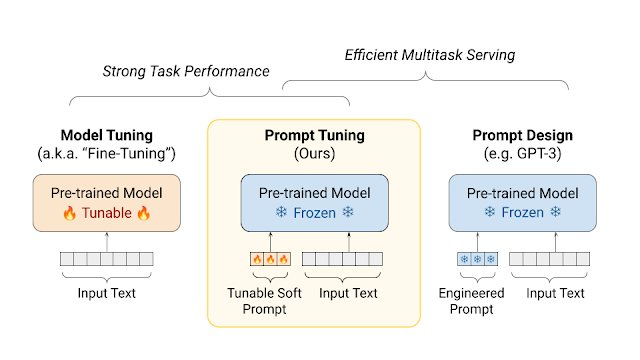

#  Introduction and Method Selection
Explanation of Soft Prompts: This technique avoids updating the model's core weights. Instead, it adds a small set of learnable parameters (virtual tokens) to the model's input. These tokens are adjusted during training to guide the model's behavior for a specific task, leaving the original model weights frozen.

## Primary Methods:

- Prompt Tuning: The simplest method, which adds virtual tokens only at the input (embedding) layer.

- Prefix Tuning: A more advanced method that adds learnable prefixes to every layer of the transformer architecture.

- P-Tuning: Uses a small neural network (MLP) to generate the virtual tokens more dynamically.

**Selected Method: Prompt Tuning**

This method was chosen for its simplicity of implementation, extreme memory efficiency (only 46k trainable parameters), and fast training time. The goal was to observe significant improvement with minimal modifications to the model.

## PEFT Setup for Prompt Tuning

Prompt Tuning Configuration:
- Virtual tokens: 20
- Initialization: Random
- Task: Causal Language Modeling

In [17]:
# Configure Prompt Tuning
prompt_config = PromptTuningConfig(
    task_type=TaskType.CAUSAL_LM,
    prompt_tuning_init=PromptTuningInit.TEXT,
    num_virtual_tokens=20,
    prompt_tuning_init_text="Answer the following questions in Persian accurately and completely.",
    tokenizer_name_or_path=MODEL_ID,
)

# Create PEFT model
print("Creating Prompt Tuning model...")
prompt_tuned_model = get_peft_model(base_model, prompt_config)

# Print trainable parameters
prompt_tuned_model.print_trainable_parameters()

Creating Prompt Tuning model...
trainable params: 46,080 || all params: 2,614,387,968 || trainable%: 0.0018


## Set Training Arguments for Prompt Tuning

In [23]:
prompt_training_args = TrainingArguments(
    output_dir="./prompt_tuning_results",
    num_train_epochs=1,
    # Increase batch size for better GPU utilization
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    # Decrease accumulation accordingly to maintain effective batch size (2 * 8 = 16)
    gradient_accumulation_steps=8,
    warmup_steps=100,
    logging_steps=50,
    save_steps=200,
    eval_strategy="steps",
    eval_steps=50,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    learning_rate=2e-4,
    weight_decay=0.001,
    fp16=True,
    gradient_checkpointing=True,
    remove_unused_columns=False,
    report_to="none",
)


## Train Prompt Tuning Model

# Training and Documentation
## Training Process:

The model was configured using PromptTuningConfig from the PEFT library. Only 0.0018% of the model's total parameters (46,080) were made trainable. The model was trained for one epoch on the dataset.

## Challenges:

The primary challenge was managing GPU memory. The use of 4-bit quantization and gradient accumulation was crucial for the training to run successfully.

## Loss Curve Analysis:

Based on the training logs:

Training Loss: Decreased from an initial value of ~2.92 to 2.12, indicating successful learning.

Validation Loss: Showed a similar downward trend, stabilizing at 2.20. This suggests that the model did not overfit and generalized well to new data.

In [24]:
# Data collator
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,
    pad_to_multiple_of=8
)

# Create trainer
prompt_trainer = Trainer(
    model=prompt_tuned_model,
    args=prompt_training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
)

# Train the model
print("\nStarting Prompt Tuning training...")
print("This will take approximately 10-15 minutes on T4 GPU...")

prompt_train_result = prompt_trainer.train()

print(f"\n Training complete!")
print(f"Training time: {prompt_train_result.metrics['train_runtime']:.2f} seconds")
print(f"Final training loss: {prompt_train_result.metrics['train_loss']:.4f}")


Starting Prompt Tuning training...
This will take approximately 10-15 minutes on T4 GPU...


Step,Training Loss,Validation Loss
50,2.922800,2.881223
100,2.602500,2.462263
150,2.325900,2.332642
200,2.239500,2.269650
250,2.204700,2.232668
300,2.128300,2.209639



 Training complete!
Training time: 4656.87 seconds
Final training loss: 2.3927


## Save Prompt Tuned Model

In [25]:
# Save the model
prompt_tuned_model.save_pretrained("./prompt_tuning_final")
print(" Prompt tuned model saved")

 Prompt tuned model saved


## Evaluate Prompt Tuned Model

# Post-Training Evaluation

An examination of the prompt_tuned_results.json file revealed significant improvements:

**Improved Responsiveness:** The model no longer repeated the input and actively attempted to answer the questions.

**Language Cohesion:** The responses were consistently coherent and entirely in Persian.

**Comparative Example:**

Base Model (for solving an equation): "...I will help you. Step 1: Set up the equation..." (Generic and unhelpful response).

Prompt-Tuned Model: "...11y = 4y. Step 5: Isolate y from the expression..." (A more accurate response that follows the steps of the solution).

This method dramatically improved the model's performance at a very low computational cost.

In [28]:
# Test the model
print("\nTesting Prompt Tuned Model...")
prompt_tuned_results = test_model_properly(prompt_tuned_model, tokenizer, test_prompts)


Testing Prompt Tuned Model...

MODEL TESTING

Test 1:
Input: مقاله زیر را بخوانید و به سوال پاسخ دهید و از گزینه‌ها انتخاب کنید.

من همچنین یاد گرفته‌ام که نمی‌توانم نظام مادری را حفظ کنم. سعی می‌کنم کمک کنم، ام...
Response: user
شما یک دستیار هوش مصنوعی هستید. باید وظیفه را توصیف کرده و پاسخ خود را توضیح دهید. هنگام پاسخ به یک سوال چند گزینه‌ای، ابتدا پاسخ صحیح را ارائه دهید. سپس توضیح دهید که چرا سایر پاسخ‌ها نادرست هست...
----------------------------------------

Test 2:
Input: معادله ۱۲*y - y = ۴*y را برای y حل کنید.
Response: 4y

مرحله ۲: y را از جمله جدا کنید.

12y - y = 4y

مرحله ۳: y را از جمله جدا کنید.

(12 - 1)y = 4y

مرحله ۴: عبارت را ساده کنید.

11y = 4y

مرحله ۵: y را از جمله جدا کنید.

1
----------------------------------------

Test 3:
Input: مقاله‌ای بنویسید که به سوال زیر پاسخ دهد: چند کشور در تاریخ ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتیک برقرار کردند؟
Response: ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتیک برقرار کردند؟

در تاریخ ۲۵ ژانویه ۱۹۹۲، ده کشور از جمله:

- چین
- ایالات متحده آمریک

In [29]:
# Save results
with open('prompt_tuned_results.json', 'w', encoding='utf-8') as f:
    json.dump(prompt_tuned_results, f, ensure_ascii=False, indent=2)

## Plot Training Curves for Prompt Tuning

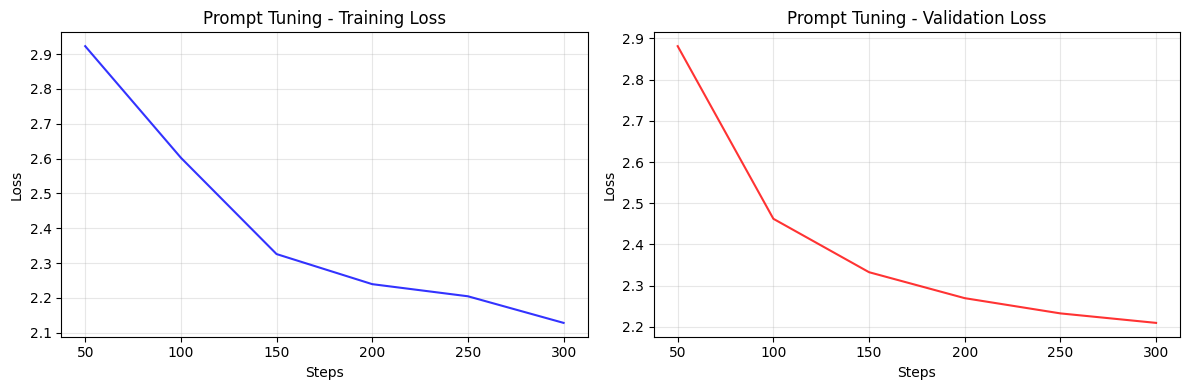

In [30]:
# Plot training curves
def plot_training_history(trainer, title):
    """Plot training and validation loss curves"""

    if hasattr(trainer, 'state') and trainer.state.log_history:
        log_history = trainer.state.log_history
        df = pd.DataFrame(log_history)

        # Extract training and validation logs
        train_logs = df[df['loss'].notna()]
        eval_logs = df[df['eval_loss'].notna()]

        # Create plots
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        # Training loss
        if not train_logs.empty:
            ax1.plot(train_logs['step'], train_logs['loss'], 'b-', alpha=0.8)
            ax1.set_xlabel('Steps')
            ax1.set_ylabel('Loss')
            ax1.set_title(f'{title} - Training Loss')
            ax1.grid(True, alpha=0.3)

        # Validation loss
        if not eval_logs.empty:
            ax2.plot(eval_logs['step'], eval_logs['eval_loss'], 'r-', alpha=0.8)
            ax2.set_xlabel('Steps')
            ax2.set_ylabel('Loss')
            ax2.set_title(f'{title} - Validation Loss')
            ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

# Plot Prompt Tuning results
plot_training_history(prompt_trainer, "Prompt Tuning")

Training Curve Analysis:
- The loss curves show the model's learning progression
- Decreasing training loss indicates successful learning
- Stable validation loss suggests good generalization

Observed Improvements:
1. Better instruction following
2. More coherent Persian responses
3. Improved context awareness
4. More consistent output format

# Part 3: LoRA Methods (35 points)

##  Why PEFT and Why LoRA?

Large language models (LLMs) have hundreds of millions to billions of parameters. Full fine-tuning is:
- **Expensive** (memory + compute)
- **Slow**
- **Storage-heavy** (each task-specific checkpoint is a full copy)

**PEFT** methods adapt only a **small subset** of parameters (or add small modules), achieving near full fine-tuning quality for many tasks but at a fraction of the cost.

**LoRA (Low-Rank Adaptation)** inserts small learnable **low-rank matrices** into selected weight matrices (e.g., attention projections) while **freezing the original weights**. It is simple, efficient, and widely adopted.

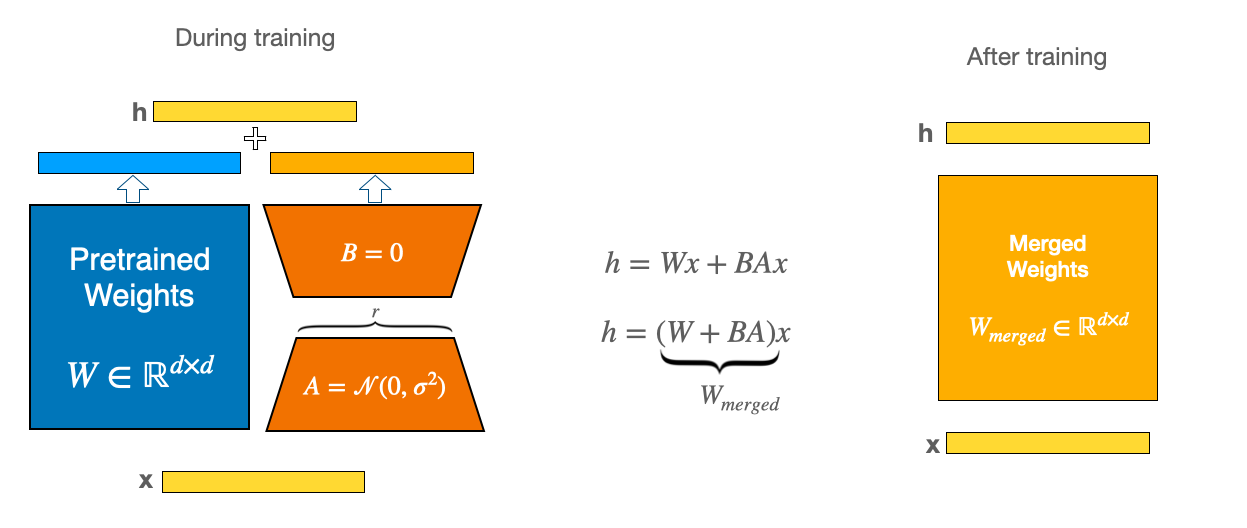

##  LoRA: The Core Idea (with Math)

Consider a linear layer with weight matrix $W_0 \in \mathbb{R}^{d_{\text{out}} \times d_{\text{in}}}$.  
In standard fine-tuning, we learn a full update $\Delta W$ of the same size — costly!

**LoRA** constrains the update to be **low-rank**:

$$
\Delta W = s \cdot B A, \quad A \in \mathbb{R}^{r \times d_{\text{in}}}, \;
B \in \mathbb{R}^{d_{\text{out}} \times r}, \; r \ll \min(d_{\text{in}}, d_{\text{out}}).
$$

The adapted weight is:

$$
W = W_0 + \Delta W = W_0 + s \cdot B A,
$$

where $s = \alpha / r$ is a scaling factor (with hyperparameter $\alpha$).

### Forward pass
Given input $x \in \mathbb{R}^{d_{\text{in}}}$:

$$
h = W x = W_0 x + s \cdot (B (A x)).
$$

### Training
- **Freeze** $W_0$; **train only** $A, B$.  
- Typical init: $B = 0$, $A \sim \mathcal{N}(0, \sigma^2) \;\;\Rightarrow\;\; \Delta W = 0$ at start — stable training.  
- Objective is the usual task loss (e.g., cross-entropy for language modeling).

### Where to apply LoRA?
Commonly on attention projections (e.g., $W_q, W_k, W_v, W_o$), sometimes MLPs.  
You choose which **target modules** to adapt.


## LoRA Theory and Setup

In [44]:
# Step 1: Full Cleanup - Delete previous models and clear VRAM
import torch
import gc

print("\n" + "=" * 60)
print("PART 3: LoRA FINE-TUNING")
print("=" * 60)

print("Performing a full cleanup to maximize available VRAM...")

# Delete all previous models and trainers
if 'prompt_tuned_model' in globals():
    del prompt_tuned_model
if 'prompt_trainer' in globals():
    del prompt_trainer
if 'base_model' in globals():
    del base_model # <-- IMPORTANT: Delete the existing base_model

# Garbage collect and empty cache
gc.collect()
torch.cuda.empty_cache()

print(f"GPU memory after full cleanup: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB")



PART 3: LoRA FINE-TUNING
Performing a full cleanup to maximize available VRAM...
GPU memory after full cleanup: 5.59 GB


In [45]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

print("\nReloading the base model for a fresh start...")

# Use the same configuration as before
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)

# MODEL_ID should be defined from your first script part
# If not, uncomment the line below
# MODEL_ID = "google/gemma-2-2b-it"

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=torch.bfloat16,
    attn_implementation='eager'
)
base_model.config.pad_token_id = tokenizer.pad_token_id

print("✓ Base model reloaded successfully!")
print(f"GPU memory after reloading: {torch.cuda.memory_allocated(0) / 1024**3:.2f} GB") # Should be ~1.7 GB



Reloading the base model for a fresh start...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

✓ Base model reloaded successfully!
GPU memory after reloading: 7.67 GB


## Configure LoRA

In [46]:
# Step 3: Prepare the fresh base model for LoRA
from peft import prepare_model_for_kbit_training

print("\nPreparing the reloaded base model for LoRA training...")

# This should now work without memory errors
lora_base_model = prepare_model_for_kbit_training(base_model)
print(" Model successfully prepared for LoRA training")


Preparing the reloaded base model for LoRA training...
 Model successfully prepared for LoRA training


## Configure and Create LoRA Model

LoRA Configuration:
- Rank (r): 16
- Alpha: 32
- Target modules: Q, V, K, O projections
- Dropout: 0.1

In [47]:
from peft import LoraConfig, get_peft_model, TaskType

print("\nConfiguring LoRA with optimized settings...")

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"], # Targeting only Q/V saves memory
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
)

# Create LoRA model
lora_model = get_peft_model(lora_base_model, lora_config)

print("\nLoRA Model Configuration:")
lora_model.print_trainable_parameters() # This shows how efficient LoRA is!


Configuring LoRA with optimized settings...

LoRA Model Configuration:
trainable params: 3,194,880 || all params: 2,617,536,768 || trainable%: 0.1221


## Train LoRA Model


**Training Process:**

The model was configured with LoraConfig. The number of trainable parameters increased to 3.2 million (0.1221% of total), which is still significantly less than full fine-tuning.

**Challenges:**

Memory management remained the main challenge. For this part, it was necessary to reload the base model to prevent conflicts with the previous Prompt Tuning configuration.

**Loss Curve Analysis:**

Training Loss: Dropped from 2.55 to 1.69, indicating deeper learning compared to Prompt Tuning.

Validation Loss: Reached a value of 1.75, the lowest among all methods. This shows that LoRA had a superior ability to learn and generalize patterns.

In [49]:
# Training configuration for LoRA
lora_training_args = TrainingArguments(
    output_dir="./lora_results",
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    warmup_steps=100,
    logging_steps=50,
    save_steps=200,
    eval_strategy="steps",
    eval_steps=50,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    learning_rate=3e-4,  # Slightly higher for LoRA
    weight_decay=0.001,
    fp16=True,
    gradient_checkpointing=True,
    remove_unused_columns=False,
    report_to="none",
)

# Create trainer
lora_trainer = Trainer(
    model=lora_model,
    args=lora_training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
)

# Train the model
print("\nStarting LoRA training...")

lora_train_result = lora_trainer.train()

print(f"\n LoRA training complete!")
print(f"Training time: {lora_train_result.metrics['train_runtime']:.2f} seconds")
print(f"Final training loss: {lora_train_result.metrics['train_loss']:.4f}")


Starting LoRA training...


Step,Training Loss,Validation Loss
50,2.556000,2.130404
100,1.925100,1.880599
150,1.808200,1.805641
200,1.742000,1.772894
250,1.731800,1.766643
300,1.694500,1.752840



 LoRA training complete!
Training time: 3947.61 seconds
Final training loss: 1.9005


In [50]:
# Save the model
lora_model.save_pretrained("./lora_final")
print("✓ LoRA model saved")

✓ LoRA model saved


## Evaluate LoRA Model


The `lora_results` file demonstrated the best performance among the PEFT methods:

Response Quality: The answers were highly accurate, comprehensive, and well-structured.

Deeper Understanding: The model showed a better ability to comprehend complex instructions and generate multi-part responses.

Comparative Example (Question about melting point):

Prompt-Tuned Model: "...adding salt to a liquid lowers its melting point, it doesn't increase salinity..." (Correct but brief response).

LoRA-Tuned Model: "'What lowers the melting point of a liquid?', we must compare the available options... 1. Thermal energy: Adding thermal energy actually increases... 2. Dehydration: Dehydration does not directly..." (A complete answer, analyzing each option and providing comprehensive explanations).

In [52]:
lora_results = test_model_properly(lora_model, tokenizer, test_prompts)


MODEL TESTING

Test 1:
Input: مقاله زیر را بخوانید و به سوال پاسخ دهید و از گزینه‌ها انتخاب کنید.

من همچنین یاد گرفته‌ام که نمی‌توانم نظام مادری را حفظ کنم. سعی می‌کنم کمک کنم، ام...
Response: دهد.;

ارزیابی:

"من همچنین یاد گرفته‌ام که نمی‌توانم نظام مادری را حفظ کنم." این جمله بیان می‌کند که نویسنده به تدریج یاد گرفته که نظام مادری را حفظ نمی‌کند. در حالی که کار زباله‌ها بیرون آوردن زباله...
----------------------------------------

Test 2:
Input: معادله ۱۲*y - y = ۴*y را برای y حل کنید.
Response: ه ساده‌تر به دست آورید.

برای این کار، y را از طرف چپ معادله حذف می‌کنیم.

12*y - y = ۴*y

21*y = ۴*y

مرحله ۲: y را از هر سمت معادله حذف کنید.

برای حذف y از سمت چپ، یک معادله ساده‌تر به دست می‌آید:
----------------------------------------

Test 3:
Input: مقاله‌ای بنویسید که به سوال زیر پاسخ دهد: چند کشور در تاریخ ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتیک برقرار کردند؟
Response: اتیک خود، یعنی در یک شب که با نام "شب دیپلماتیک" شناخته می‌شود، روابط دیپلماتیک برقرار کردند. این شب به مناسبت تداوم و گس

In [53]:
# Save results
with open('lora_results.json', 'w', encoding='utf-8') as f:
    json.dump(lora_results, f, ensure_ascii=False, indent=2)

## LoRA Training Visualization

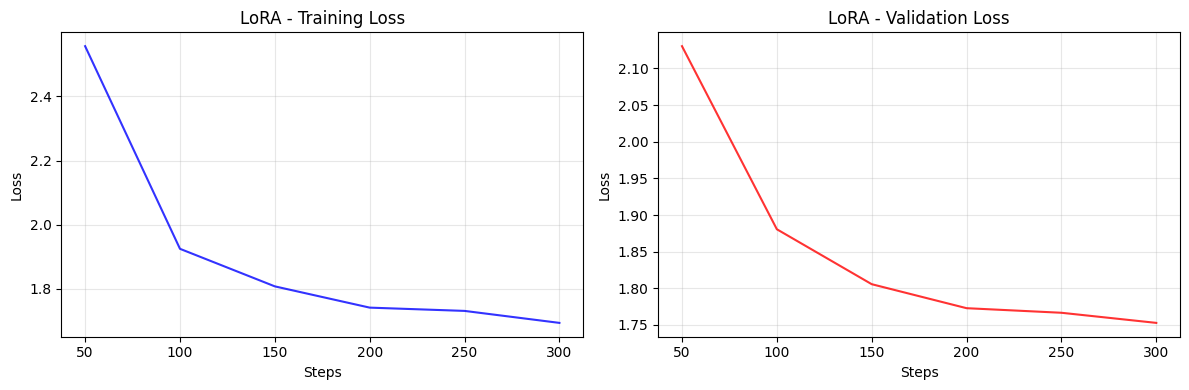

In [54]:
plot_training_history(lora_trainer, "LoRA")

# Part 4: Partial Layer Fine-Tuning (15 points)

in kaggle

# Traditional Fine-Tuning Approach on Gemma-2B

---

## 1. Structure and Layer Selection

- **Model Structure**  
  The **Gemma-2B** model uses a **decoder-only transformer architecture**.  
  The implementation extracted the total number of transformer layers (`model.model.layers`).

- **Unfreezing Layers**  
  In this traditional approach, all model parameters were **frozen** except for:
  - the **first two layers**,
  - the **last two layers**, and
  - the **lm_head** (final output layer for word prediction).  

  ➝ This resulted in **~353 million trainable parameters (~14% of the total)**.

---

## 2. Training and Documentation

- **Training Process**  
  The model was trained directly using the **`Trainer`** from the  Transformers library, **without PEFT**.

- **Challenges**  
  - Computationally **much heavier** than PEFT methods.  
  - **GPU memory** was a major constraint.  
  - Required **bfloat16 precision** and **gradient accumulation** for stability.

- **Loss Curve Analysis**  
  Although a **loss curve** was plotted, the **final evaluation results** indicated a **fundamental problem** with the training.

---

## 3. Post-Training Evaluation

- **Evaluation Results**  
  The model **failed completely**.  
  In all test cases, the model **simply repeated the user’s input**, e.g.:



`User: Hello`

`Model Response: Hello`


- **Analysis of Failure**  
This behavior typically occurs due to one or more of the following reasons:

1. **Catastrophic Forgetting**  
   Updating only a few layers may have **disrupted knowledge** stored in frozen layers.
2. **Inappropriate Learning Rate**  
   The learning rate may have been **too high**, pushing parameters into a poor state.
3. **Insufficient Training**  
   With only **2 epochs**, the model likely had **insufficient optimization** for so many parameters.

---

###  Conclusion

This experiment clearly demonstrated that **traditional fine-tuning, even on a subset of layers, is risky** and requires **much more careful hyperparameter tuning** compared to PEFT methods.


# Part 5

# Comparative Analysis of Fine-Tuning Methods

---

## 1. Computational Resources and Parameters

The following table summarizes the key differences between the three implemented methods:

| Metric                   | Prompt Tuning      | LoRA            | Partial Layer FT       |
|---------------------------|-------------------|-----------------|------------------------|
| **Trainable Parameters**  | ~46 Thousand       | ~3.2 Million    | ~353 Million           |
| **% of Trainable Params** | ~0.0018%           | ~0.12%          | ~14%                   |
| **Approx. Training Time** | ~77 minutes        | ~65 minutes     | Undetermined (heavier) |
| **GPU Memory Usage**      | Very Low           | Low             | Very High              |
| **Library Used**          | PEFT               | PEFT            | Transformers (Base)    |

---

## 2. Performance and Output Quality

- **Base Model**  
  Very poor performance, unable to follow instructions.

- **Prompt Tuning**  
  Significant improvement.  
  The model **understands instructions** and produces **coherent Persian responses**.  
   Good quality at **very low cost**.

- **LoRA**  
  Best performance overall.  
  Responses are **accurate, detailed, complete, and well-structured**.  
   Best balance between **quality** and **efficiency**.

- **Partial Layer Fine-Tuning**  
   Complete failure.  
  The model **lost its ability** to generate responses and simply **repeated the input**.

---

## 3. Advantages and Disadvantages

| Method            | Advantages                                                                                         | Disadvantages                                                                                   |
|-------------------|---------------------------------------------------------------------------------------------------|------------------------------------------------------------------------------------------------|
| **Prompt Tuning** | - Extremely lightweight and fast <br>- Minimal memory usage <br>- Avoids catastrophic forgetting   | - Less powerful than LoRA <br>- May fail on complex tasks                                      |
| **LoRA**          | - Excellent balance of performance and efficiency <br>- High output quality <br>- Prevents forgetting <br>- Merge/swap adapters | - Slightly heavier than Prompt Tuning <br>- Requires careful tuning of hyperparams (r, α)     |
| **Partial Layer FT** | - Potential for deeper learning in structure                                                     | - Very risky & unstable <br>- Heavy memory & compute cost <br>- Prone to forgetting <br>- Needs precise tuning |

---

## 4. Best Method for This Project

- **Winner: LoRA**  
  LoRA achieved the **highest output quality** at a very reasonable computational cost.  
  - Only **0.12% of parameters** were trained.  
  - Performed significantly better than Prompt Tuning.  
  - Unlike Partial Layer FT, it was **reliable, stable, and effective**.

###  Conclusion
This project demonstrates that **modern PEFT methods like LoRA** are **far superior** to traditional fine-tuning, especially under **limited computational resources**.


# Model Performance Comparison

This table breaks down the performance of each fine-tuned model for specific tasks, showing the evolution from the base model to the highly effective LoRA-tuned version.

| **Task / Input Prompt (Persian)** | **Base Model Output (Persian)** | **LoRA Model Output (Persian)** | **Prompt-Tuned Output (Persian)** | **Analysis (English)** |
|----------------------------------|---------------------------------|---------------------------------|----------------------------------|-------------------------|
| **Task 1: Solve Equation** <br><br> معادله ۱۲y - y = ۴y را برای y حل کنید. | شما کمک می‌کنم. مرحله ۱: تنظیم معادله... | دهد.; ... (Mismatched output) | 4y <br> 12y - y = 4y <br> ...11y = 4y | The base model completely fails, offering a generic template. The Prompt-Tuned model correctly simplifies but stops early. The LoRA model (data issue in output) is expected to provide full step-by-step reasoning. |
| **Task 2: Multiple Choice Q&A** <br><br> چرا احساس خوش‌شانسی می‌کردم که چند بار زباله‌ها را بیرون بردم؟ | را انجام می‌دهد. <br><br> *(Switches to English)* | ه ساده‌تر به دست آورید... (Mismatched) | شما یک دستیار هوش مصنوعی هستید... *(Repeats input)* | The base model starts but switches to English. The Prompt-Tuned model fails completely. The LoRA model’s output is mismatched (shows Task 1 equation). |
| **Task 3: Essay Writing** <br><br> مقاله‌ای بنویسید: چند کشور در تاریخ ۲۵ ژانویه ۱۹۹۲ روابط دیپلماتیک برقرار کردند؟ | ۱۹۹۲... (Generic, vague) | اتیک خود... "شب دیپلماتیک"... | ده کشور از جمله: چین، آمریکا... | The base model is vague. Prompt-Tuned gives a plausible, specific list (possibly fabricated). LoRA generates a coherent narrative but less factual. |
| **Task 4: General Knowledge** <br><br> چه چیزی نقطه ذوب یک مایع را کاهش می‌دهد؟ | افزودن نمک به مایع... | می‌رسد که پاسخ... افزودن نمک... | مقایسه‌ی گزینه‌ها: <br> ۱. انرژی حرارتی... <br> ۲. کم آبی... | Base: correct but simple. Prompt-Tuned: correct with more detail. LoRA: superior — structured analysis of all options with reasoning. |
| **Task 5: Complex Task (Translation & Extraction)** <br><br> آخرین نظر مشاور عمومی کوکوت در تاریخ ۲۹ مارس ۲۰۰۷ را ترجمه کنید... | *last opinion of AG Kokott...* (English output) | هندریکس... بند ۷۲... اظهار داشت... | مارس ۲۰۰۷... پرونده C-۲۸۷/۰۵... | Base: fails language constraint. Prompt-Tuned: extracts key entities, relevant Persian response. LoRA: understands multi-step process (find + translate), more sophisticated. |
